In [1]:
import pandas as pd

df = pd.read_csv("/content/sample_data/2017_jun_final - 2017_jun_final.csv")

print(df.head())


   N                    Посада Мова програмування Спеціалізація  \
0  1        Junior QA engineer                NaN     Manual QA   
1  2        Junior QA engineer                NaN     Manual QA   
2  3         Software Engineer            C#/.NET           NaN   
3  4         Software Engineer         JavaScript           NaN   
4  5  Senior Software Engineer         JavaScript           NaN   

  Загальний досвід роботи Досвід роботи на поточному місці  \
0                     0.5                              0.5   
1         менше 3 місяців                  менше 3 місяців   
2                       4                                1   
3                       5                                4   
4       10 і більше років                              0.5   

   Зарплата на місяць  Зміна зарплати за 12 місяців   Місто   Розмір компанії  \
0                 400                             0  Харків        до 10 осіб   
1                 430                           130  Харків  б

In [5]:
print(df.shape)

(8704, 25)


In [6]:
print(df.dtypes)

N                                     int64
Посада                               object
Мова програмування                   object
Спеціалізація                        object
Загальний досвід роботи              object
Досвід роботи на поточному місці     object
Зарплата на місяць                    int64
Зміна зарплати за 12 місяців          int64
Місто                                object
Розмір компанії                      object
Тип компанії                         object
Стать                                object
Вік                                   int64
Освіта                               object
Університет                          object
Ще студент                             bool
Рівень англійської                   object
Предметна область                    object
Дата заповнення                      object
User.Agent                           object
exp                                 float64
current_job_exp                     float64
salary                          

In [7]:
df.isnull().sum()

,0
N,0
Посада,0
Мова програмування,3850
Спеціалізація,7219
Загальний досвід роботи,0
Досвід роботи на поточному місці,0
Зарплата на місяць,0
Зміна зарплати за 12 місяців,0
Місто,0
Розмір компанії,0


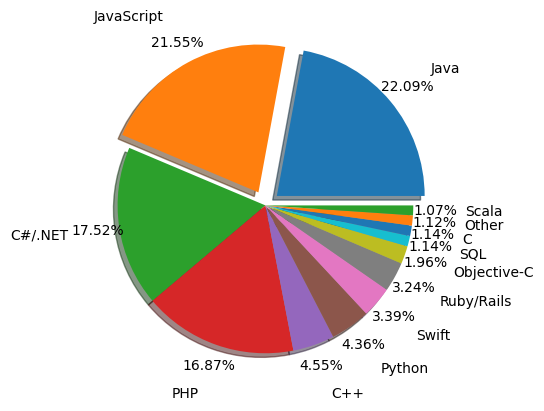

In [8]:
%matplotlib inline
import matplotlib.pyplot as plt

data = df['Мова програмування'].value_counts(normalize=True)*100
data_more_1 = data[data >= 1]
len_data = len(data_more_1)
explode = [0] * len_data
explode[0] = 0.1
explode[1] = 0.1
plt.pie(
    data_more_1,
    labels=data_more_1.index,
    shadow=True,
    explode=explode,
    autopct="%.2f%%",
    pctdistance=1.15,
    labeldistance=1.35,
)

plt.show()


In [10]:

colDrop = [col for col in df.columns if df[col].isna().any() and col != 'Мова програмування']
df = df.drop(columns=colDrop)
#df_cleaned.to_csv('file_cleaned.csv', index=False)

In [11]:
print(df.shape)

(8704, 20)


In [12]:
df.isnull().sum()

,0
N,0
Посада,0
Мова програмування,3850
Загальний досвід роботи,0
Досвід роботи на поточному місці,0
Зарплата на місяць,0
Зміна зарплати за 12 місяців,0
Місто,0
Розмір компанії,0
Тип компанії,0


In [13]:
df = df.dropna()

In [14]:
print(df.shape)

(4854, 20)


In [15]:
df.isnull().sum()

,0
N,0
Посада,0
Мова програмування,0
Загальний досвід роботи,0
Досвід роботи на поточному місці,0
Зарплата на місяць,0
Зміна зарплати за 12 місяців,0
Місто,0
Розмір компанії,0
Тип компанії,0


In [16]:
print(df.columns.tolist())


['N', 'Посада', 'Мова програмування', 'Загальний досвід роботи', 'Досвід роботи на поточному місці', 'Зарплата на місяць', 'Зміна зарплати за 12 місяців', 'Місто', 'Розмір компанії', 'Тип компанії', 'Стать', 'Вік', 'Освіта', 'Ще студент', 'Рівень англійської', 'Дата заповнення', 'User.Agent', 'exp', 'current_job_exp', 'salary']


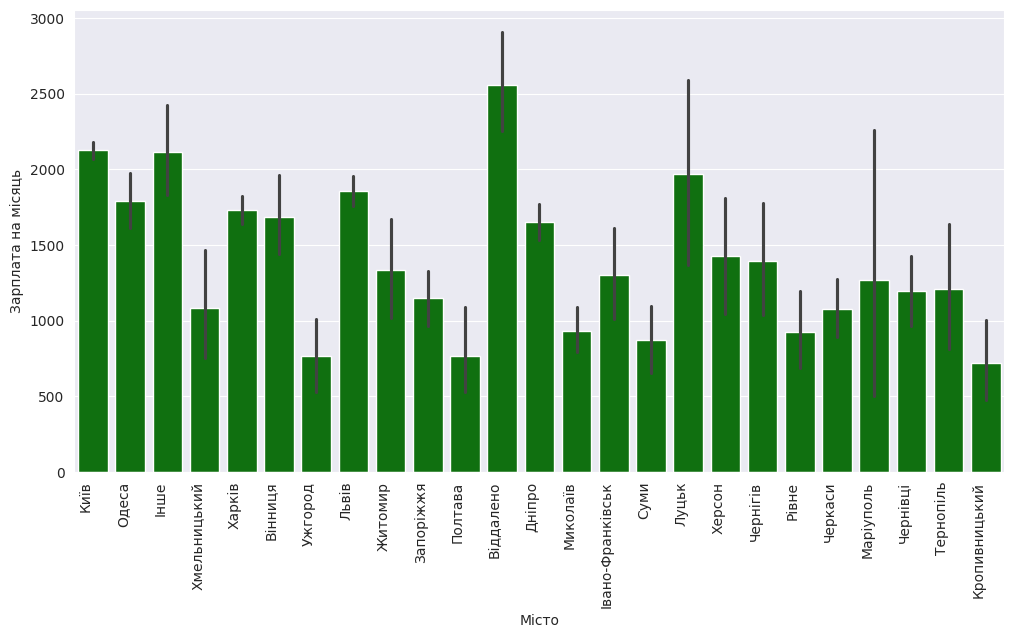

In [19]:
%matplotlib inline
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
sns.barplot(data=df, x ='Місто',y='Зарплата на місяць', color = 'green')
plt.xticks(rotation=90, ha='right')
plt.show()

In [20]:
df[df['Мова програмування'] == 'Python'].to_csv('python_data.csv', index=False)

In [21]:
df_Phyton = pd.read_csv("/content/python_data.csv")

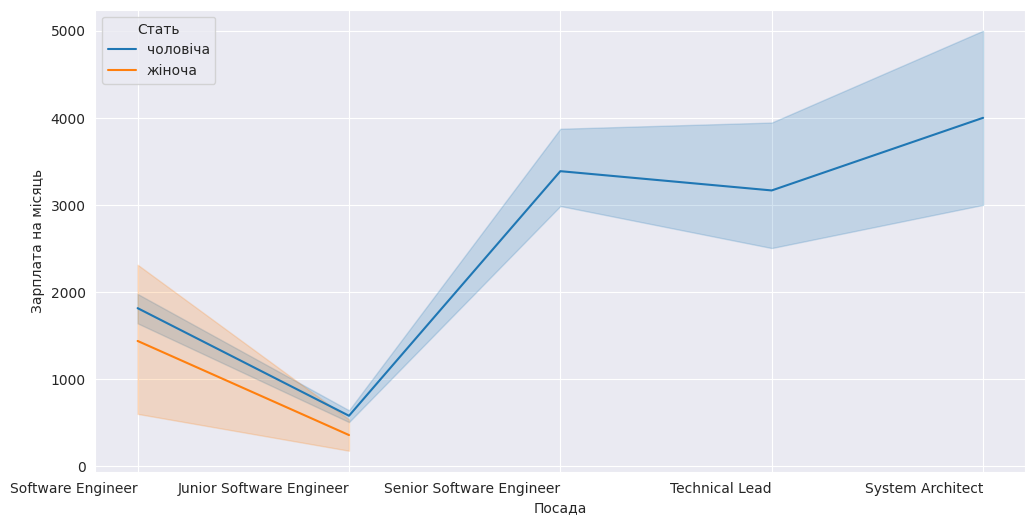

In [38]:
%matplotlib inline

sns.set_style("darkgrid")
sns.lineplot(x='Посада', y='Зарплата на місяць', hue="Стать", data=df_Phyton)
plt.xticks(rotation=0, ha='right')
plt.show()


In [28]:
print(df_Phyton.shape)

(207, 20)


In [29]:
df_Groupby = df_Phyton.groupby(["Посада"])

In [30]:
df_Groupby.agg({"Зарплата на місяць": ["max", "min"]})

Зарплата на місяць      
                                        max   min
Посада                                           
Junior Software Engineer               1250   100
Senior Software Engineer               9200  1300
Software Engineer                      5400   500
System Architect                       5000  3000
Technical Lead                         6200  1425

In [31]:
df_Groupby = (
    df_Phyton.groupby(['Посада'])
    .agg({'Зарплата на місяць': ['max', 'min']})
    .reset_index()
)
df_Groupby.columns = ['Посада', 'max', 'min']
def fill_avg_salary(row):
     return (row['min'] + row['max']) / 2

In [1]:
%matplotlib inline
posada = df_Groupby['Посада']
max_salary = df_Groupby['max']
min_salary = df_Groupby['min']
df_line = pd.DataFrame({'Посада': posada, 'max': max_salary, 'min': min_salary})
plt.figure(figsize=(12, 6))
sns.lineplot(data=df_line, x='Посада', y='max', marker='*', label='Max')
sns.lineplot(data=df_line, x='Посада', y='min', marker='*', label='Min')
plt.xticks(rotation=90, ha='right')
plt.show()



NameError: name 'df_Groupby' is not defined

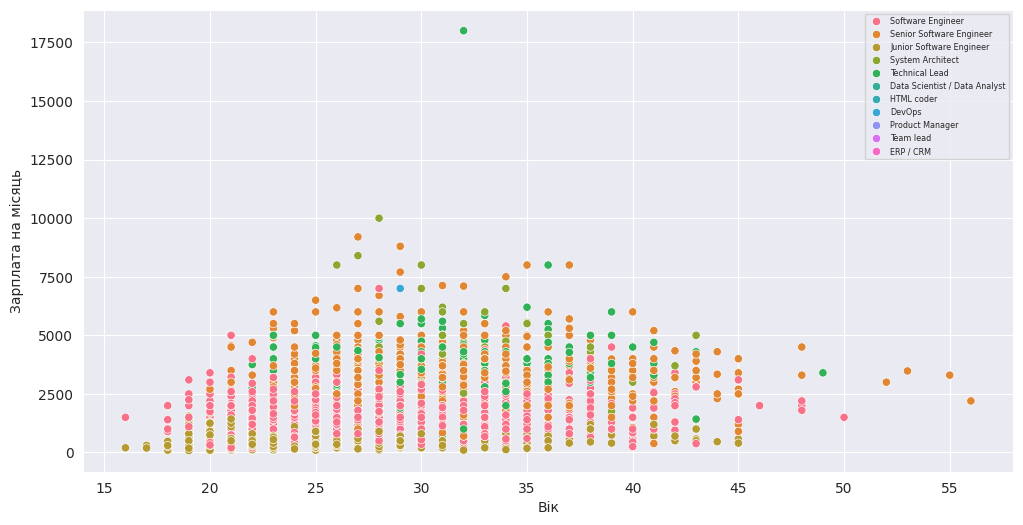

In [33]:
%matplotlib inline
plt.figure(figsize=(12, 6))
sns.scatterplot(x='Вік', y='Зарплата на місяць', hue='Посада', data=df)
plt.legend(fontsize='xx-small')
plt.show()
#sns.set_context(context="paper", font_scale=2, rc=None)
#sns.color_palette(palette="Set2", n_colors=2, desat=None)



In [35]:
df_Groupby['avg'] = df_Groupby.apply(fill_avg_salary, axis=1)
print(df_Groupby)

                     Посада   max   min     avg
0  Junior Software Engineer  1250   100   675.0
1  Senior Software Engineer  9200  1300  5250.0
2         Software Engineer  5400   500  2950.0
3          System Architect  5000  3000  4000.0
4            Technical Lead  6200  1425  3812.5


In [36]:
print(df_Groupby['avg'].describe())

count       5.000000
mean     3337.500000
std      1700.091909
min       675.000000
25%      2950.000000
50%      3812.500000
75%      4000.000000
max      5250.000000
Name: avg, dtype: float64


In [37]:
df_Groupby.to_csv('clean_table.csv', index=False)